# 1/ Librairie

In [2]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuration graphique
sns.set_theme(style="whitegrid")

# Déterminer la racine du projet
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = PROJECT_ROOT / "data" / "raw" / "creditcard.csv"

print("Projet :", PROJECT_ROOT)
print("Dataset :", DATA_PATH)
print("Fichier présent :", DATA_PATH.exists())

Projet : c:\Users\benja\OneDrive\Bureau\test_jupyter\projet_MLops
Dataset : c:\Users\benja\OneDrive\Bureau\test_jupyter\projet_MLops\data\raw\creditcard.csv
Fichier présent : True


# 2/ Charger le dataset

In [3]:
if not DATA_PATH.is_file():
    raise FileNotFoundError(
        f"Dataset introuvable : {DATA_PATH}"
    )

df = pd.read_csv(DATA_PATH, delimiter= ";")

print("Dimensions :", df.shape)
print("\nPremières transactions :")
display(df.head())

print("\nTypes des colonnes :")
df.info()

Dimensions : (284807, 31)

Premières transactions :


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0,-1.359807,-0.072781,2.536347,1.378155,0.070000,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0



Types des colonnes :
<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  int64  
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21 

# 3/ Verifier la qualité des données

In [4]:
# Valeurs manquantes
missing = df.isna().sum()
# print(missing)

print("Valeurs manquantes :")
print(missing[missing > 0])

# Lignes exactement identiques
duplicates = df.duplicated().sum()


print("\nNombre de doublons :", duplicates)

# Statistiques descriptives
display(df.describe().T)

# Vérifier les valeurs de la cible
print("\nClasses présentes :")
print(df["Class"].unique())

Valeurs manquantes :
Series([], dtype: int64)

Nombre de doublons : 1081


,count,mean,std,min,25%,50%,75%,max
Time,284807.0,9.481386e+04,47488.145955,0.000000,54201.500000,84692.000000,139320.500000,172792.000000
V1,284807.0,1.175161e-15,1.958696,-56.407510,-0.920373,0.018109,1.315642,2.454930
V2,284807.0,3.384974e-16,1.651309,-72.715728,-0.598550,0.065486,0.803724,22.057729
V3,284807.0,-1.379537e-15,1.516255,-48.325589,-0.890365,0.179846,1.027196,9.382558
V4,284807.0,2.094852e-15,1.415869,-5.683171,-0.848640,-0.019847,0.743341,16.875344
V5,284807.0,1.433675e-06,1.380247,-113.743307,-0.691597,-0.054332,0.611926,34.801666
V6,284807.0,1.494498e-15,1.332271,-26.160506,-0.768296,-0.274187,0.398565,73.301626
V7,284807.0,-5.620335e-16,1.237094,-43.557242,-0.554076,0.040103,0.570436,120.589494
V8,284807.0,1.149614e-16,1.194353,-73.216718,-0.208630,0.022358,0.327346,20.007208
V9,284807.0,-2.414189e-15,1.098632,-13.434066,-0.643098,-0.051429,0.597139,15.594995



Classes présentes :
[0 1]


# 4/ Etudier désequilibre des classes

In [5]:
class_counts = df["Class"].value_counts().sort_index()

class_percent = (
    df["Class"].value_counts(normalize=True)
    .sort_index() * 100
)

print("Répartition des classes :")
print(class_counts)

print("\nPourcentage :")
print(class_percent)

plt.figure(figsize=(7, 4))

sns.countplot(
    data=df,
    x="Class",
    order=[0, 1]
)

plt.title("Répartition des transactions")
plt.xlabel("Classe : 0 = normale, 1 = fraude")
plt.ylabel("Nombre de transactions")

plt.tight_layout()
plt.show()

: 

# 5/ Statistiques par classe

In [5]:
amount_stats = df.groupby("Class")["Amount"].agg(
    ["count", "mean", "median", "std", "min", "max"]
)

display(amount_stats)

,count,mean,median,std,min,max
Class,,,,,,
0,284315,88.291022,22.00,250.105092,0.0,25691.16
1,492,122.211321,9.25,256.683288,0.0,2125.87


# 6/ Histogrammes des montants

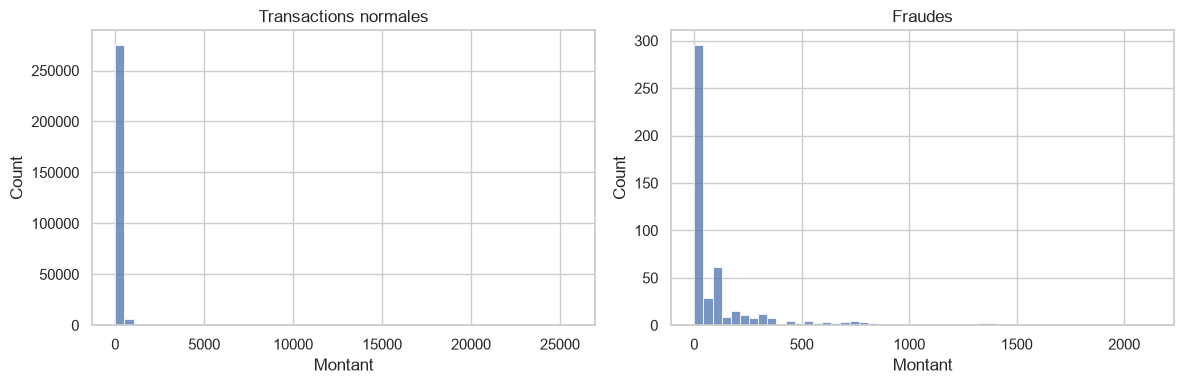

In [9]:
fig, axes = plt.subplots(
    1, 2, figsize=(12, 4)
)

for classe, ax in zip([0, 1], axes):
    subset = df.loc[
        df["Class"] == classe, "Amount"
    ]

    sns.histplot(
        subset,
        bins=50,
        ax=ax
    )

    ax.set_title(
        "Transactions normales"
        if classe == 0
        else "Fraudes"
    )

    ax.set_xlabel("Montant")

plt.tight_layout()
plt.show()

# 7/ Corrélation des variables avec la cible

Corrélations avec la fraude :


V17   -0.326481
V14   -0.302544
V12   -0.260593
V10   -0.216883
V16   -0.196539
V3    -0.192961
V7    -0.187257
V11    0.154876
V4     0.133447
V18   -0.111485
V1    -0.101347
V9    -0.097733
V5    -0.094974
V2     0.091289
V6    -0.043643
Name: Class, dtype: float64

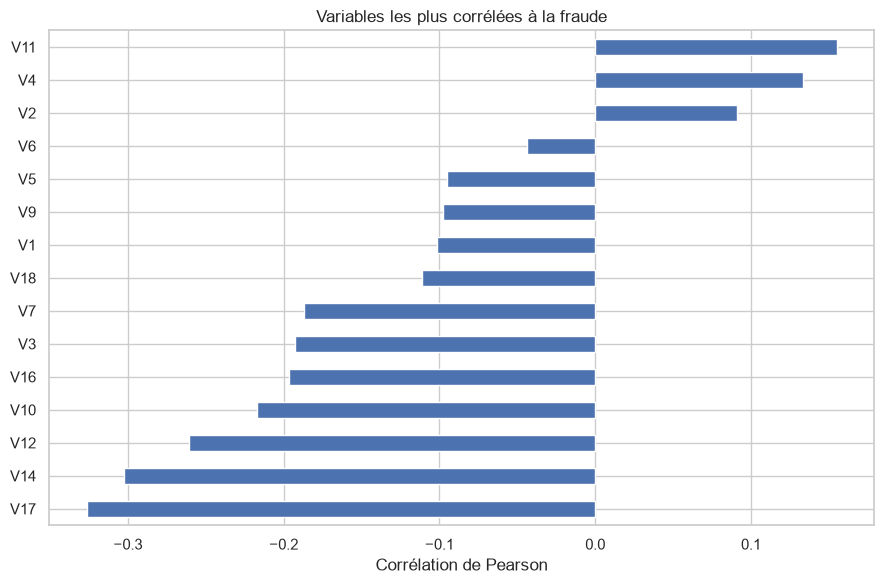

In [8]:
corr = df.corr(numeric_only=True)

target_corr = (
    corr["Class"]
    .drop("Class")
    .sort_values(key=lambda x: x.abs(), ascending=False)
)

print("Corrélations avec la fraude :")
display(target_corr.head(15))

plt.figure(figsize=(9, 6))

target_corr.head(15).sort_values().plot(
    kind="barh"
)

plt.title("Variables les plus corrélées à la fraude")
plt.xlabel("Corrélation de Pearson")

plt.tight_layout()
plt.show()

# 8/ Découpage et sauvegarde

In [7]:
# Trier chronologiquement
df_sorted = df.sort_values(
    "Time",
    kind="stable"
).reset_index(drop=True)

n = len(df_sorted)

train_end = int(n * 0.70)
val_end = int(n * 0.85)

train_df = df_sorted.iloc[:train_end].copy()
val_df = df_sorted.iloc[train_end:val_end].copy()
test_df = df_sorted.iloc[val_end:].copy()

# Contrôle de la répartition
for name, dataset in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    print(
        name,
        ":", len(dataset),
        "transactions | Fraudes :",
        dataset["Class"].sum(),
        "| Taux :",
        round(dataset["Class"].mean() * 100, 4),
        "%"
    )

# Sauvegarder les jeux de données
processed_dir = PROJECT_ROOT / "data" / "processed"
processed_dir.mkdir(parents=True, exist_ok=True)

train_df.to_parquet(
    processed_dir / "train.parquet",
    index=False
)

val_df.to_parquet(
    processed_dir / "validation.parquet",
    index=False
)

test_df.to_parquet(
    processed_dir / "test.parquet",
    index=False
)

print("Fichiers Parquet créés.")

Train : 199364 transactions | Fraudes : 384 | Taux : 0.1926 %
Validation : 42721 transactions | Fraudes : 56 | Taux : 0.1311 %
Test : 42722 transactions | Fraudes : 52 | Taux : 0.1217 %
Fichiers Parquet créés.
